In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

In [2]:
K = tf.keras
L = tf.keras.layers

In [3]:
#dataset
root = "fashion mnist"
names = [c for c in sorted(os.listdir(root)) if c != "train"]        # skip the stray "train" folder
kw = dict(image_size=(64,64),batch_size=32,validation_split=0.2,seed=42,class_names=names)
tr = K.utils.image_dataset_from_directory(root,subset="training",**kw)
va = K.utils.image_dataset_from_directory(root,subset="validation",**kw)
#tr = tr.take(60)                  # optional: faster on a slow CPU

Found 12656 files belonging to 10 classes.
Using 10125 files for training.
Found 12656 files belonging to 10 classes.
Using 2531 files for validation.


In [4]:
#load base model
base = K.applications.VGG16(include_top=False,input_shape=(64,64,3),weights="vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5")
base.trainable = False
model = K.Sequential([L.Input((64,64,3)), L.Lambda(K.applications.vgg16.preprocess_input), base, L.GlobalAveragePooling2D(),L.Dense(256,activation="relu"), L.Dropout(0.3), L.Dense(len(va.class_names),activation="softmax")])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                      │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 2, 2, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,848,586 (56.64 MB)

 Trainable params: 133,898 (523.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [5]:
#compile
model.compile(optimizer=K.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = model.fit(tr, validation_data=va, epochs=4)

Epoch 1/4
317/317 ━━━━━━━━━━━━━━━━━━━━ 86s 267ms/step - accuracy: 0.6291 - loss: 3.4010 - val_accuracy: 0.8001 - val_loss: 0.6343
Epoch 2/4
317/317 ━━━━━━━━━━━━━━━━━━━━ 81s 255ms/step - accuracy: 0.7934 - loss: 0.6170 - val_accuracy: 0.8222 - val_loss: 0.5493
Epoch 3/4
317/317 ━━━━━━━━━━━━━━━━━━━━ 81s 254ms/step - accuracy: 0.8354 - loss: 0.4688 - val_accuracy: 0.8289 - val_loss: 0.5314
Epoch 4/4
317/317 ━━━━━━━━━━━━━━━━━━━━ 82s 258ms/step - accuracy: 0.8585 - loss: 0.3942 - val_accuracy: 0.8242 - val_loss: 0.5348


In [6]:
#evaluate
model.evaluate(va)
X, y = zip(*va.as_numpy_iterator())
X, y = np.concatenate(X), np.concatenate(y) 
pred = model.predict(X).argmax(1)
print(classification_report(y, pred, target_names=va.class_names))

80/80 ━━━━━━━━━━━━━━━━━━━━ 16s 204ms/step - accuracy: 0.8276 - loss: 0.5221
80/80 ━━━━━━━━━━━━━━━━━━━━ 16s 200ms/step
              precision    recall  f1-score   support

  Ankle-boot       0.97      0.89      0.93       205
         Bag       0.92      0.94      0.93       171
        Coat       0.74      0.75      0.74       338
       Dress       0.79      0.80      0.80       322
    Pullover       0.82      0.79      0.80       380
      Sandal       0.96      0.92      0.94       244
       Shirt       0.49      0.55      0.52       198
     Sneaker       0.88      0.99      0.93       239
 T-shirt-top       0.79      0.76      0.78       237
     Trouser       0.98      0.93      0.95       197

    accuracy                           0.82      2531
   macro avg       0.83      0.83      0.83      2531
weighted avg       0.83      0.82      0.83      2531



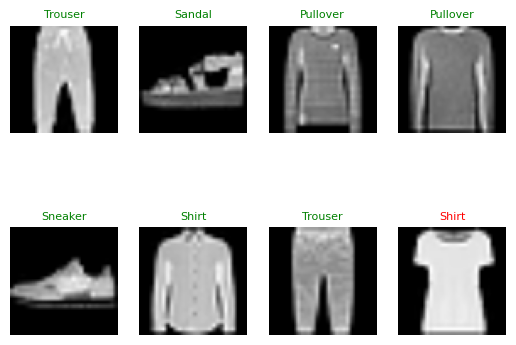

In [7]:
#plot
for i in range(8):
    plt.subplot(2, 4, i + 1); plt.imshow(X[i].astype("uint8")); plt.axis("off")
    plt.title(va.class_names[pred[i]], color="g" if pred[i] == y[i] else "r", fontsize=8)
plt.show()

In [8]:
#fine tune
base.trainable = True
for l in base.layers[:-4]:
    l.trainable = False
model.compile(optimizer=K.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(tr, validation_data=va, epochs=2)
print(model.evaluate(va))

Epoch 1/2
317/317 ━━━━━━━━━━━━━━━━━━━━ 103s 319ms/step - accuracy: 0.8808 - loss: 0.3353 - val_accuracy: 0.8538 - val_loss: 0.4715
Epoch 2/2
317/317 ━━━━━━━━━━━━━━━━━━━━ 105s 330ms/step - accuracy: 0.9132 - loss: 0.2386 - val_accuracy: 0.8609 - val_loss: 0.4766
80/80 ━━━━━━━━━━━━━━━━━━━━ 17s 212ms/step - accuracy: 0.8629 - loss: 0.4500
[0.4765681028366089, 0.8609245419502258]


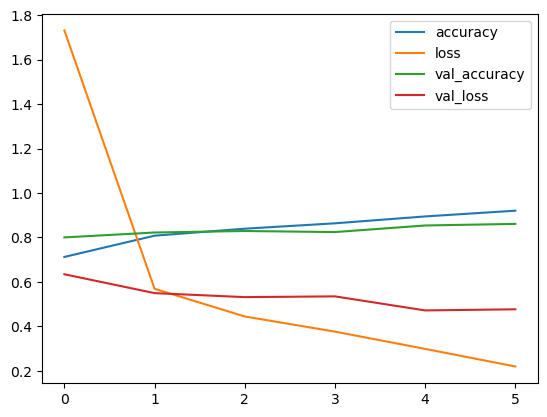

In [9]:
#compare
pd.concat([pd.DataFrame(h1.history), pd.DataFrame(h2.history)], ignore_index=True).plot()
plt.show()